# Project Showcase: End-to-End Audio Anti-Spoofing (ASVspoof 2019 LA)

This project presents a dual-paradigm machine learning and deep learning pipeline designed to detect voice spoofing attacks (synthetic and replayed speech) using the ASVspoof 2019 Logical Access (LA) database.

### System Architecture
* **Feature-Engineered Baseline:** Extracting compressed statistical summaries of LFCC, MFCC, and CQT features evaluated via a tuned **HistGradientBoosting** classifier.
* **Deep Spatio-Temporal Model:** Training a **Light Convolutional Neural Network (LCNN)** on 2D LFCC spectrogram tensors with dynamic delta and delta-delta coefficients.
* **Statistical Validation:** Computing group-level significance via Welch's t-tests with Benjamini-Hochberg FDR adjustments to analyze feature discriminative power.
```


### 1. Environment & Package Setup
This block configures the runtime environment, pinning dependencies for signal processing, modeling, statistical evaluation, and progress logging.


In [41]:
!pip -q install librosa soundfile scipy scikit-learn pandas matplotlib seaborn tqdm


### 2. Standard Imports & Diagnostics
Importing core modules and setting logging controls to ensure a clean console output during execution.


In [42]:
import os
import random
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf

from scipy.stats import ttest_ind, skew, kurtosis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
print("Imports complete.")

Imports complete.



### 3. File System & Cloud Drive Integration
Mounts the storage volume, unpacks the local ASVspoof dataset mirror, and establishes robust absolute path directories for training, development, and evaluation segments.


In [43]:
from google.colab import drive
# Force unmount before mounting to avoid stale mount points or connection issues
try:
    drive.flush_and_unmount()
    print("Unmounted existing drive successfully.")
except Exception as e:
    print("No active drive mount to unmount or error during unmount:", e)

drive.mount('/content/drive', force_remount=True)

!unzip -q -n "/content/drive/MyDrive/ASVSpoof2019LA/LA" -d "/content/ASVspoof"

DATA_ROOT = Path('/content/ASVspoof/LA')

TRAIN_AUDIO_DIR = DATA_ROOT / 'ASVspoof2019_LA_train' / 'flac'
DEV_AUDIO_DIR   = DATA_ROOT / 'ASVspoof2019_LA_dev' / 'flac'
EVAL_AUDIO_DIR  = DATA_ROOT / 'ASVspoof2019_LA_eval' / 'flac'

TRAIN_PROTOCOL = DATA_ROOT / 'ASVspoof2019_LA_cm_protocols' / 'ASVspoof2019.LA.cm.train.trn.txt'
DEV_PROTOCOL   = DATA_ROOT / 'ASVspoof2019_LA_cm_protocols' / 'ASVspoof2019.LA.cm.dev.trl.txt'
EVAL_PROTOCOL  = DATA_ROOT / 'ASVspoof2019_LA_cm_protocols' / 'ASVspoof2019.LA.cm.eval.trl.txt'

OUTPUT_DIR = Path('/content/drive/MyDrive/ASVspoof_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT exists:", DATA_ROOT.exists())
print("Train audio:", TRAIN_AUDIO_DIR.exists())
print("Dev audio:", DEV_AUDIO_DIR.exists())
print("Eval audio:", EVAL_AUDIO_DIR.exists())
print("Train protocol:", TRAIN_PROTOCOL.exists())
print("Dev protocol:", DEV_PROTOCOL.exists())
print("Eval protocol:", EVAL_PROTOCOL.exists())

Unmounted existing drive successfully.
Mounted at /content/drive
DATA_ROOT exists: True
Train audio: True
Dev audio: True
Eval audio: True
Train protocol: True
Dev protocol: True
Eval protocol: True



### 4. Deterministic Controls & Acceleration Setup
Enforcing strict random state seeds across Python, NumPy, and PyTorch to guarantee reproducible runs while establishing CUDA hardware acceleration.


In [44]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

Device: cuda



### 5. Acoustic DSP Hyperparameters
Establishing signal processing invariants tailored to speech anti-spoofing standards (16 kHz sample rate, 10 ms window hop size, and fixed 400-frame spectrogram limits).


In [45]:
SR = 16000
N_FFT = 512
HOP_LENGTH = 160
N_MFCC = 20
N_LFCC = 20
MAX_AUDIO_SECONDS = 10  # cap very long recordings; set None to disable
MAX_LFCC_FRAMES = 400  # fixed time dimension for LCNN input


### 6. ASVspoof Protocol Metadata Parser
Reads five-column protocol records to structure data subsets, mapping string class labels to target identifiers (`0` for genuine speech, `1` for spoofing attacks).


In [46]:
def read_protocol(protocol_path):
    records = []
    with open(protocol_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            if len(parts) < 5:
                continue
            speaker_id = parts[0]
            file_id = parts[1]
            system_id = parts[2]
            attack_id = parts[3]
            label = parts[4]
            records.append({
                "speaker_id": speaker_id,
                "file_id": file_id,
                "system_id": system_id,
                "attack_id": attack_id,
                "label": label
            })
    return pd.DataFrame(records)

def encode_labels(df):
    df = df.copy()
    df['label_text'] = df['label'].astype(str).str.lower()
    mapping = {'bonafide': 0, 'bona fide': 0, 'genuine': 0, 'spoof': 1}
    df['y'] = df['label_text'].map(mapping)
    return df

train_df = encode_labels(read_protocol(TRAIN_PROTOCOL))
dev_df = encode_labels(read_protocol(DEV_PROTOCOL))
eval_df = encode_labels(read_protocol(EVAL_PROTOCOL)) if EVAL_PROTOCOL.exists() else pd.DataFrame()

print("Train protocol:", train_df.shape, train_df['y'].value_counts(dropna=False).to_dict())
print("Dev protocol:", dev_df.shape, dev_df['y'].value_counts(dropna=False).to_dict())
print("Eval protocol:", eval_df.shape)
display(train_df.head())

Train protocol: (25380, 7) {1: 22800, 0: 2580}
Dev protocol: (24844, 7) {1: 22296, 0: 2548}
Eval protocol: (71237, 7)


,speaker_id,file_id,system_id,attack_id,label,label_text,y
0,LA_0079,LA_T_1138215,-,-,bonafide,bonafide,0
1,LA_0079,LA_T_1271820,-,-,bonafide,bonafide,0
2,LA_0079,LA_T_1272637,-,-,bonafide,bonafide,0
3,LA_0079,LA_T_1276960,-,-,bonafide,bonafide,0
4,LA_0079,LA_T_1341447,-,-,bonafide,bonafide,0



### 7. File Alignment & Protocol Verification
Verifies file matches between metadata records and local audio assets to prevent downstream pipeline exceptions.


In [47]:
def report_protocol(df, name, audio_dir):
    if df.empty:
        print(f'{name}: EMPTY')
        return
    print(f'\\n{name}: rows={len(df)}')
    print('Labels:', df['label'].value_counts(dropna=False).to_dict())
    print('Unknown encoded labels:', int(df['y'].isna().sum()))
    sample_path = audio_dir / f"{df.iloc[0]['file_id']}.flac"
    print('Sample audio path:', sample_path)
    print('Sample exists:', sample_path.exists())

report_protocol(train_df, 'TRAIN', TRAIN_AUDIO_DIR)
report_protocol(dev_df, 'DEV', DEV_AUDIO_DIR)
report_protocol(eval_df, 'EVAL', EVAL_AUDIO_DIR)

\nTRAIN: rows=25380
Labels: {'spoof': 22800, 'bonafide': 2580}
Unknown encoded labels: 0
Sample audio path: /content/ASVspoof/LA/ASVspoof2019_LA_train/flac/LA_T_1138215.flac
Sample exists: True
\nDEV: rows=24844
Labels: {'spoof': 22296, 'bonafide': 2548}
Unknown encoded labels: 0
Sample audio path: /content/ASVspoof/LA/ASVspoof2019_LA_dev/flac/LA_D_1047731.flac
Sample exists: True
\nEVAL: rows=71237
Labels: {'spoof': 63882, 'bonafide': 7355}
Unknown encoded labels: 0
Sample audio path: /content/ASVspoof/LA/ASVspoof2019_LA_eval/flac/LA_E_2834763.flac
Sample exists: True



### 8. Robust Audio I/O Kernel
Reads disk recordings to floating-point NumPy arrays, automatically downmixing stereo to mono and trimming long clips to cap resource demands.


In [48]:
def load_audio(path, sr=SR):
    y, _ = librosa.load(path, sr=sr, mono=True, duration=MAX_AUDIO_SECONDS)
    if y.size == 0:
        raise ValueError(f'Empty audio: {path}')
    return y.astype(np.float32)


### 9. Digital Signal Processing & Summary Extraction
Calculates LFCC, MFCC, CQT-approximated representations, and key spectral descriptors. These temporal matrices are compressed into fixed-size statistical signatures (mean, standard deviation, skewness, kurtosis).


In [49]:
from scipy.fftpack import dct

def _filterbank(y, sr, n_filters=20, scale='mel', n_fft=N_FFT, hop=HOP_LENGTH):
    S = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop)) ** 2
    if scale == 'mel':
        fb = librosa.filters.mel(sr=sr, n_fft=n_fft, n_mels=n_filters)
    else:
        # Linear-frequency triangular filters.
        freqs = np.linspace(0, sr / 2, n_fft // 2 + 1)
        centers = np.linspace(0, sr / 2, n_filters + 2)
        fb = np.zeros((n_filters, len(freqs)), dtype=np.float32)
        for i in range(n_filters):
            left, center, right = centers[i:i+3]
            if center > left:
                fb[i] = np.maximum(fb[i], (freqs-left)/(center-left))
            if right > center:
                fb[i] = np.minimum(fb[i], (right-freqs)/(right-center))
            fb[i] = np.clip(fb[i], 0, 1)
    energies = fb @ S
    return np.log(np.maximum(energies, 1e-10))

def extract_lfcc(y, sr=SR, n_lfcc=N_LFCC):
    log_energy = _filterbank(y, sr, n_filters=n_lfcc, scale='linear')
    return dct(log_energy, type=2, axis=0, norm='ortho').astype(np.float32)

def extract_mfcc(y, sr=SR, n_mfcc=N_MFCC):
    return librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH).astype(np.float32)

def extract_cqcc_like(y, sr=SR, n_coeffs=20):
    C = np.abs(librosa.cqt(y, sr=sr, hop_length=HOP_LENGTH, n_bins=84, bins_per_octave=12))
    log_cqt = np.log(np.maximum(C, 1e-8))
    return dct(log_cqt, type=2, axis=0, norm='ortho')[:n_coeffs].astype(np.float32)

def extract_spectral(y, sr=SR):
    return {
        'spectral_centroid': librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0],
        'spectral_bandwidth': librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0],
        'spectral_rolloff': librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0],
        'zero_crossing_rate': librosa.feature.zero_crossing_rate(y, hop_length=HOP_LENGTH)[0],
        'rms': librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    }

def summarize_matrix(matrix, prefix):
    feats = {}
    for i, row in enumerate(matrix):
        safe_row = np.asarray(row, dtype=np.float64)
        safe_row = safe_row[np.isfinite(safe_row)]
        if safe_row.size == 0:
            vals = [0.0] * 4
        else:
            vals = [
                float(np.mean(safe_row)),
                float(np.std(safe_row)),
                float(skew(safe_row)) if safe_row.size > 2 else 0.0,
                float(kurtosis(safe_row)) if safe_row.size > 3 else 0.0
            ]
        for stat, val in zip(['mean', 'std', 'skew', 'kurtosis'], vals):
            feats[f'{prefix}_{i}_{stat}'] = val
    return feats

def extract_summary_features(audio_path):
    y = load_audio(audio_path)
    features = {}
    features.update(summarize_matrix(extract_lfcc(y), 'lfcc'))
    features.update(summarize_matrix(extract_mfcc(y), 'mfcc'))
    try:
        features.update(summarize_matrix(extract_cqcc_like(y), 'cqcc_like'))
    except Exception as e:
        # CQT can fail on very short signals; preserve row shape with zeros.
        features.update(summarize_matrix(np.zeros((20, 1), dtype=np.float32), 'cqcc_like'))
    for name, values in extract_spectral(y).items():
        values = np.asarray(values)
        features[f'{name}_mean'] = float(np.mean(values))
        features[f'{name}_std'] = float(np.std(values))
    return features


### 10. High-Performance Feature Caching Engine
Extracts and caches global summary features to persistent storage to optimize workflow efficiency across runtime sessions.


In [40]:
def build_feature_table(protocol_df, audio_dir, split_name, cache_path=None):
    if cache_path and Path(cache_path).exists():
        cached = pd.read_csv(cache_path)
        print(f'Loaded cached {split_name} features:', cached.shape)
        return cached

    rows = []
    skipped = []
    valid_df = protocol_df.dropna(subset=['y']).copy()
    for row in tqdm(valid_df.to_dict('records'), desc=f'Extracting {split_name}'):
        audio_path = Path(audio_dir) / f"{row['file_id']}.flac"
        if not audio_path.exists():
            skipped.append((row['file_id'], 'missing'))
            continue
        try:
            feats = extract_summary_features(audio_path)
            feats.update({
                'file_id': row['file_id'],
                'speaker_id': row['speaker_id'],
                'label': int(row['y']),
                'label_text': row['label']
            })
            rows.append(feats)
        except Exception as exc:
            skipped.append((row['file_id'], str(exc)[:150]))

    result = pd.DataFrame(rows)
    if cache_path:
        result.to_csv(cache_path, index=False)
    print(f'{split_name}: features={result.shape}; skipped={len(skipped)}')
    if skipped[:5]:
        print('First skipped examples:', skipped[:5])
    return result

TRAIN_FEATURES_CSV = OUTPUT_DIR / 'train_summary_features.csv'
DEV_FEATURES_CSV = OUTPUT_DIR / 'dev_summary_features.csv'
EVAL_FEATURES_CSV = OUTPUT_DIR / 'eval_summary_features.csv'

train_features = build_feature_table(train_df, TRAIN_AUDIO_DIR, 'train', TRAIN_FEATURES_CSV)
dev_features = build_feature_table(dev_df, DEV_AUDIO_DIR, 'dev', DEV_FEATURES_CSV)
eval_features = build_feature_table(eval_df, EVAL_AUDIO_DIR, 'eval', EVAL_FEATURES_CSV) if not eval_df.empty else pd.DataFrame()

display(train_features.head())

Extracting train:   0%|          | 0/25380 [00:00<?, ?it/s]

train: features=(21844, 254); skipped=3536
First skipped examples: [('LA_T_9107429', 'missing'), ('LA_T_9152126', 'missing'), ('LA_T_9188299', 'missing'), ('LA_T_9258514', 'missing'), ('LA_T_9341221', 'missing')]


Extracting dev:   0%|          | 0/24844 [00:00<?, ?it/s]

dev: features=(21843, 254); skipped=3001
First skipped examples: [('LA_D_8923486', 'missing'), ('LA_D_8966044', 'missing'), ('LA_D_9015485', 'missing'), ('LA_D_9113203', 'missing'), ('LA_D_9134844', 'missing')]


Extracting eval:   0%|          | 0/71237 [00:00<?, ?it/s]

eval: features=(21844, 254); skipped=49393
First skipped examples: [('LA_E_8877452', 'missing'), ('LA_E_6828287', 'missing'), ('LA_E_6977360', 'missing'), ('LA_E_5932896', 'missing'), ('LA_E_5849185', 'missing')]


,lfcc_0_mean,lfcc_0_std,lfcc_0_skew,lfcc_0_kurtosis,lfcc_1_mean,lfcc_1_std,lfcc_1_skew,lfcc_1_kurtosis,lfcc_2_mean,lfcc_2_std,...,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,file_id,speaker_id,label,label_text
0,-23.036118,19.012262,-0.304409,-1.148082,8.961670,7.789085,-0.145342,-0.898499,-0.170720,3.340221,...,3911.398121,1815.735795,0.179380,0.120548,0.054035,0.079925,LA_T_1138215,LA_0079,0,bonafide
1,-25.747376,17.891334,-0.064262,-1.088232,10.018928,7.219872,-0.295250,-0.525234,0.124888,2.857510,...,3640.696023,1820.794353,0.157281,0.119516,0.049282,0.082500,LA_T_1271820,LA_0079,0,bonafide
2,-26.739610,20.499743,-0.061830,-1.461826,4.768995,7.465825,0.266178,-0.317842,0.626136,2.964679,...,4817.564655,1711.474986,0.235914,0.186627,0.032829,0.067781,LA_T_1272637,LA_0079,0,bonafide
3,-19.086358,17.548238,-0.553331,-1.030122,8.417302,7.783815,-0.198616,-0.756313,-0.322442,4.197128,...,3799.867021,2050.277354,0.203987,0.179118,0.070543,0.076737,LA_T_1276960,LA_0079,0,bonafide
4,-20.493996,16.608634,0.108362,-1.433938,7.558369,6.301519,0.118049,-0.170335,1.393336,2.127862,...,4092.337571,1949.748336,0.178843,0.120197,0.062433,0.093204,LA_T_1341447,LA_0079,0,bonafide


In [63]:
import os

# List of cached CSV paths
paths_to_check = [TRAIN_FEATURES_CSV, DEV_FEATURES_CSV, EVAL_FEATURES_CSV]

for path in paths_to_check:
    if path.exists():
        size = path.stat().st_size
        print(f"{path.name}: exists, size = {size} bytes")
        # Delete files that are empty or contain only a tiny header/blank space (< 10 bytes)
        if size <= 10:
            print(f"-> Deleting corrupted/empty cached file: {path.name}")
            path.unlink()
    else:
        print(f"{path.name}: does not exist")

train_summary_features.csv: exists, size = 106734712 bytes
dev_summary_features.csv: exists, size = 106729019 bytes
eval_summary_features.csv: exists, size = 106954453 bytes



### 11. Feature Matrix Diagnostics
Validates the dimensions, label balanced splits, and data completeness of cached data files before launching the models.


In [51]:
print('Train:', train_features.shape)
print('Dev:', dev_features.shape)
print('Eval:', eval_features.shape)
print('Train label counts:', train_features['label'].value_counts().to_dict() if not train_features.empty else {})
print('Missing values in train:', int(train_features.isna().sum().sum()) if not train_features.empty else 0)

Train: (21844, 254)
Dev: (21843, 254)
Eval: (21844, 254)
Train label counts: {1: 19625, 0: 2219}
Missing values in train: 0



### 12. Statistical Analytics: Feature Separation
Applies Welch's t-tests and Cohen's *d* effect size metrics on extracted features to rank their statistical discriminative capacity between bona fide and spoof audio.


In [52]:
def cohens_d(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x, y = x[np.isfinite(x)], y[np.isfinite(y)]
    if len(x) < 2 or len(y) < 2:
        return np.nan
    pooled_var = ((len(x)-1)*np.var(x, ddof=1) + (len(y)-1)*np.var(y, ddof=1)) / (len(x)+len(y)-2)
    if pooled_var <= 0:
        return 0.0
    return (np.mean(y) - np.mean(x)) / np.sqrt(pooled_var)

def analyze_features(df):
    if df.empty or 'label' not in df:
        return pd.DataFrame()
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    numeric_cols = [c for c in numeric_cols if c != 'label']
    bona = df[df['label'] == 0]
    spoof = df[df['label'] == 1]
    results = []
    for col in numeric_cols:
        x = bona[col].replace([np.inf, -np.inf], np.nan).dropna().values
        y = spoof[col].replace([np.inf, -np.inf], np.nan).dropna().values
        if len(x) < 2 or len(y) < 2:
            continue
        stat, p = ttest_ind(x, y, equal_var=False, nan_policy='omit')
        d = cohens_d(x, y)
        results.append({
            'feature': col, 'n_bonafide': len(x), 'n_spoof': len(y),
            'mean_bonafide': np.mean(x), 'mean_spoof': np.mean(y),
            't_statistic': stat, 'p_value': p, 'cohens_d': d, 'abs_cohens_d': abs(d)
        })
    return pd.DataFrame(results).sort_values('abs_cohens_d', ascending=False)

stats_df = analyze_features(train_features)
display(stats_df.head(20))

,feature,n_bonafide,n_spoof,mean_bonafide,mean_spoof,t_statistic,p_value,cohens_d,abs_cohens_d
114,mfcc_8_skew,2219,19625,-0.659295,-0.201042,-53.684894,0.000000e+00,0.916247,0.916247
177,cqcc_like_4_std,2219,19625,2.277625,2.702143,-61.205532,0.000000e+00,0.871193,0.871193
93,mfcc_3_std,2219,19625,26.387946,32.286660,-52.119346,0.000000e+00,0.836570,0.836570
173,cqcc_like_3_std,2219,19625,3.313099,3.935209,-52.374155,0.000000e+00,0.829364,0.829364
118,mfcc_9_skew,2219,19625,-0.710889,-0.298140,-46.599756,0.000000e+00,0.828603,0.828603
242,spectral_bandwidth_mean,2219,19625,1689.391226,1552.587060,49.109114,0.000000e+00,-0.817912,0.817912
108,mfcc_7_mean,2219,19625,-6.895302,-11.956900,46.208947,0.000000e+00,-0.807172,0.807172
72,lfcc_18_mean,2219,19625,0.002236,-0.077358,37.668903,1.921217e-253,-0.756205,0.756205
170,cqcc_like_2_skew,2219,19625,-0.099804,0.273522,-53.364651,0.000000e+00,0.740987,0.740987
182,cqcc_like_5_skew,2219,19625,0.147447,-0.077408,31.530784,1.453528e-186,-0.701908,0.701908



### 13. Multiple Testing Correction
Applies Benjamini-Hochberg False Discovery Rate (FDR) control at $\alpha = 0.05$ to suppress type-1 errors across high-dimensional feature spaces.


In [53]:
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    out = np.empty(n, dtype=float)
    out[order] = adjusted
    return out

if not stats_df.empty:
    stats_df['p_adj_fdr'] = benjamini_hochberg(stats_df['p_value'].fillna(1.0).values)
    stats_df['significant_fdr_0_05'] = stats_df['p_adj_fdr'] < 0.05
    stats_df.to_csv(OUTPUT_DIR / 'feature_statistical_analysis.csv', index=False)
    print('Saved statistical results.')
display(stats_df.head(20))

Saved statistical results.


,feature,n_bonafide,n_spoof,mean_bonafide,mean_spoof,t_statistic,p_value,cohens_d,abs_cohens_d,p_adj_fdr,significant_fdr_0_05
114,mfcc_8_skew,2219,19625,-0.659295,-0.201042,-53.684894,0.000000e+00,0.916247,0.916247,0.000000e+00,True
177,cqcc_like_4_std,2219,19625,2.277625,2.702143,-61.205532,0.000000e+00,0.871193,0.871193,0.000000e+00,True
93,mfcc_3_std,2219,19625,26.387946,32.286660,-52.119346,0.000000e+00,0.836570,0.836570,0.000000e+00,True
173,cqcc_like_3_std,2219,19625,3.313099,3.935209,-52.374155,0.000000e+00,0.829364,0.829364,0.000000e+00,True
118,mfcc_9_skew,2219,19625,-0.710889,-0.298140,-46.599756,0.000000e+00,0.828603,0.828603,0.000000e+00,True
242,spectral_bandwidth_mean,2219,19625,1689.391226,1552.587060,49.109114,0.000000e+00,-0.817912,0.817912,0.000000e+00,True
108,mfcc_7_mean,2219,19625,-6.895302,-11.956900,46.208947,0.000000e+00,-0.807172,0.807172,0.000000e+00,True
72,lfcc_18_mean,2219,19625,0.002236,-0.077358,37.668903,1.921217e-253,-0.756205,0.756205,2.401521e-252,True
170,cqcc_like_2_skew,2219,19625,-0.099804,0.273522,-53.364651,0.000000e+00,0.740987,0.740987,0.000000e+00,True
182,cqcc_like_5_skew,2219,19625,0.147447,-0.077408,31.530784,1.453528e-186,-0.701908,0.701908,1.397623e-185,True



### 14. Empirical Density Analysis
Plots Kernel Density Estimates (KDE) for the top statistically ranked features to visually verify separation bounds.


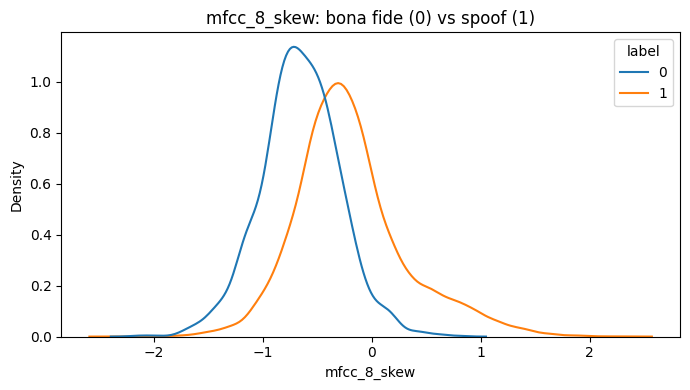

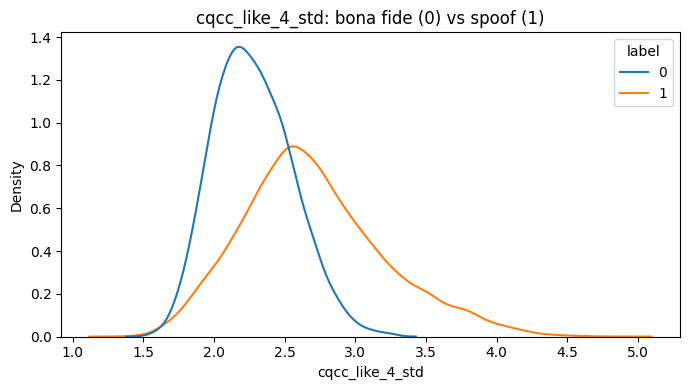

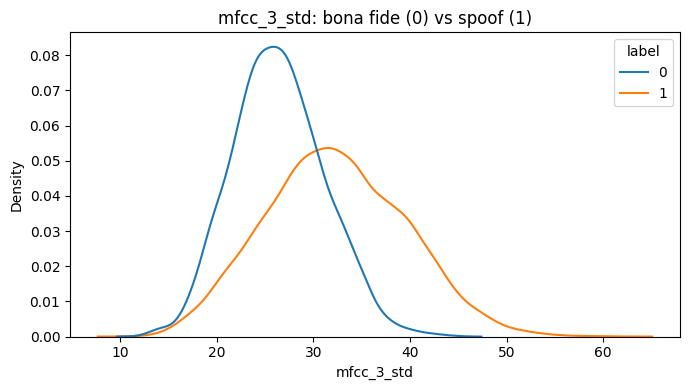

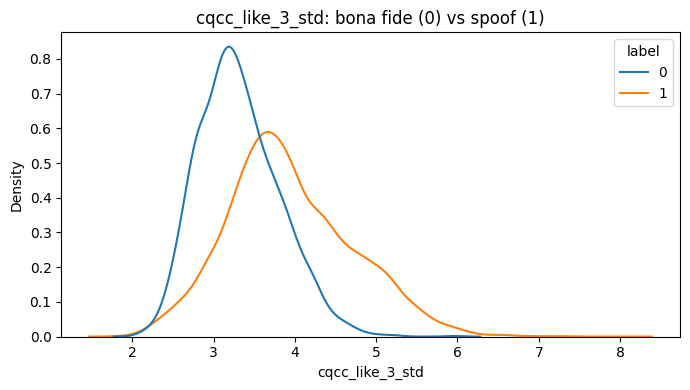

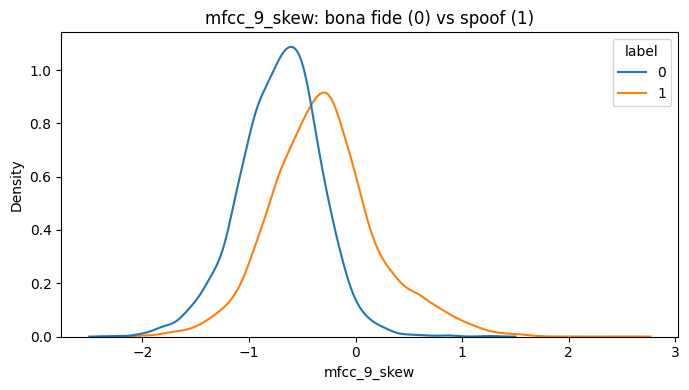

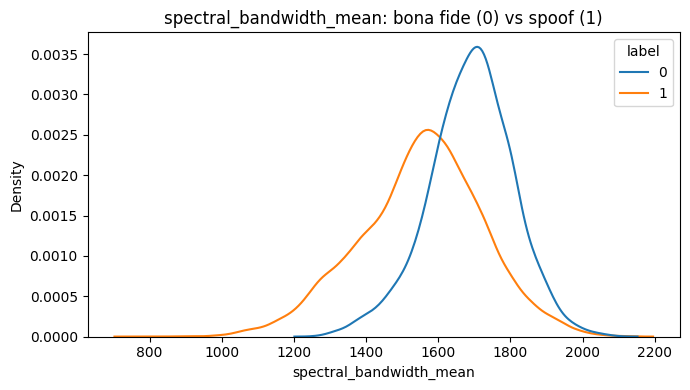

In [54]:
if not stats_df.empty:
    top_features = stats_df['feature'].head(6).tolist()
    for feat in top_features:
        plt.figure(figsize=(7, 4))
        sns.kdeplot(data=train_features, x=feat, hue='label', common_norm=False, fill=False)
        plt.title(f'{feat}: bona fide (0) vs spoof (1)')
        plt.tight_layout()
        plt.show()
else:
    print('No statistical results to plot.')

```markdown
### 15. Baseline Preparation: Imputation & Partitioning
Prepares feature tables for standard modeling by isolating numeric variables, replacing infinite values, and performing median imputation.
```

In [55]:
META_COLS = {'file_id', 'speaker_id', 'label_text', 'label'}
feature_cols = [c for c in train_features.columns if c not in META_COLS and pd.api.types.is_numeric_dtype(train_features[c])]

def make_xy(df, feature_cols):
    X = df.reindex(columns=feature_cols).replace([np.inf, -np.inf], np.nan)
    return X, df['label'].astype(int).values

X_train, y_train = make_xy(train_features, feature_cols)
X_dev, y_dev = make_xy(dev_features, feature_cols)
X_train = X_train.fillna(X_train.median()).fillna(0)
X_dev = X_dev.fillna(X_train.median()).fillna(0)
print(X_train.shape, X_dev.shape)

(21844, 250) (21843, 250)



### 16. Baseline Evaluation: HistGradientBoosting
Trains a gradient-boosted ensemble model on statistical summary features to establish a high-efficiency performance baseline.


              precision    recall  f1-score   support

    bonafide       0.97      0.83      0.90      2255
       spoof       0.98      1.00      0.99     19588

    accuracy                           0.98     21843
   macro avg       0.98      0.91      0.94     21843
weighted avg       0.98      0.98      0.98     21843

Accuracy: 0.9803140594240718
ROC-AUC: 0.9971893059101753


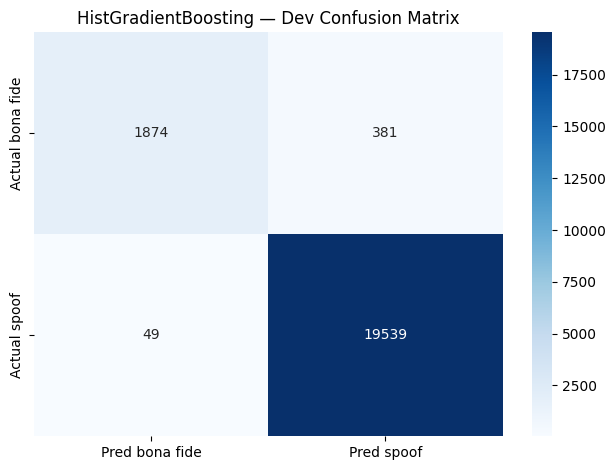

In [56]:
hgb = HistGradientBoostingClassifier(
    max_iter=250, learning_rate=0.08, max_leaf_nodes=31,
    l2_regularization=0.1, random_state=SEED
)
hgb.fit(X_train, y_train)
dev_pred_hgb = hgb.predict(X_dev)
dev_prob_hgb = hgb.predict_proba(X_dev)[:, 1]

print(classification_report(y_dev, dev_pred_hgb, target_names=['bonafide', 'spoof'], zero_division=0))
print('Accuracy:', accuracy_score(y_dev, dev_pred_hgb))
print('ROC-AUC:', roc_auc_score(y_dev, dev_prob_hgb) if len(np.unique(y_dev)) == 2 else 'N/A')

cm = confusion_matrix(y_dev, dev_pred_hgb, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred bona fide', 'Pred spoof'],
            yticklabels=['Actual bona fide', 'Actual spoof'])
plt.title('HistGradientBoosting — Dev Confusion Matrix')
plt.tight_layout()
plt.show()


### 17. Security Metrics Evaluation Suite
Computes security-oriented metrics, specifically Tracking Equal Error Rates (EER) and False Positive Rates (FPR), to align evaluation with biometric industry standards.


In [57]:
def calculate_metrics(y_true, y_pred, y_score=None, model_name='model'):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    metrics = {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_spoof': precision_score(y_true, y_pred, zero_division=0),
        'recall_spoof': recall_score(y_true, y_pred, zero_division=0),
        'f1_spoof': f1_score(y_true, y_pred, zero_division=0),
        'FPR_bonafide_flagged_spoof': fp / (fp + tn) if (fp + tn) else np.nan,
        'FNR_spoof_missed_as_bonafide': fn / (fn + tp) if (fn + tp) else np.nan
    }
    if y_score is not None and len(np.unique(y_true)) == 2:
        fpr, tpr, thresholds = roc_curve(y_true, y_score)
        fnr = 1 - tpr
        idx = int(np.nanargmin(np.abs(fpr - fnr)))
        metrics['roc_auc'] = roc_auc_score(y_true, y_score)
        metrics['eer_approx'] = float((fpr[idx] + fnr[idx]) / 2)
    else:
        metrics['roc_auc'] = np.nan
        metrics['eer_approx'] = np.nan
    return metrics

hgb_metrics = calculate_metrics(y_dev, dev_pred_hgb, dev_prob_hgb, 'HistGradientBoosting')
print(hgb_metrics)

{'model': 'HistGradientBoosting', 'accuracy': 0.9803140594240718, 'precision_spoof': 0.9808734939759036, 'recall_spoof': 0.9974984684500715, 'f1_spoof': 0.9891161283790625, 'FPR_bonafide_flagged_spoof': np.float64(0.16895787139689578), 'FNR_spoof_missed_as_bonafide': np.float64(0.0025015315499285276), 'roc_auc': np.float64(0.9971893059101753), 'eer_approx': 0.022113633986507876}



### 18. Spatio-Temporal PyTorch Loader
Constructs 2D audio tensors containing static, delta, and delta-delta LFCC coefficients. Integrates a custom collate function to handle corrupt audio files.


In [65]:
def prepare_lfcc_tensor(audio_path):
    y = load_audio(audio_path)
    lfcc = extract_lfcc(y, n_lfcc=N_LFCC)
    delta = librosa.feature.delta(lfcc, order=1)
    delta2 = librosa.feature.delta(lfcc, order=2)
    stack = np.stack([lfcc, delta, delta2], axis=0).astype(np.float32)  # (3, coefficients, frames)

    # Pad or crop the time dimension to a fixed length.
    T = stack.shape[-1]
    if T < MAX_LFCC_FRAMES:
        stack = np.pad(stack, ((0, 0), (0, 0), (0, MAX_LFCC_FRAMES - T)), mode='constant')
    else:
        stack = stack[:, :, :MAX_LFCC_FRAMES]
    return stack

class LFCCDataset(Dataset):
    def __init__(self, protocol_df, audio_dir):
        self.items = []
        for row in protocol_df.dropna(subset=['y']).to_dict('records'):
            path = Path(audio_dir) / f"{row['file_id']}.flac"
            if path.exists():
                self.items.append((path, int(row['y']), row['file_id']))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, file_id = self.items[idx]
        try:
            tensor = prepare_lfcc_tensor(path)
            return torch.from_numpy(tensor), torch.tensor(label, dtype=torch.long), file_id
        except Exception as e:
            print(f"\n[Dataset Warning] Skipping corrupt file {path.name}: {e}")
            return None

def safe_collate_fn(batch):
    # Filter out None elements returned by corrupted files
    batch = [b for b in batch if b is not None]
    if len(batch) == 0:
        return None
    return torch.utils.data.dataloader.default_collate(batch)

BATCH_SIZE = 16
train_ds = LFCCDataset(train_df, TRAIN_AUDIO_DIR)
dev_ds = LFCCDataset(dev_df, DEV_AUDIO_DIR)

# Added safe_collate_fn to ignore corrupt frames
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available(), collate_fn=safe_collate_fn)
dev_loader = DataLoader(dev_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available(), collate_fn=safe_collate_fn)

print('LCNN train examples:', len(train_ds), 'dev examples:', len(dev_ds))

LCNN train examples: 21844 dev examples: 21844



### 19. Deep Learning Model: Light CNN (LCNN)
Implements a Light CNN (LCNN) architecture using Max-Feature-Map (MFM) activations to capture fine spectral patterns while suppressing acoustic noise.


In [59]:
class MaxFeatureMap2D(nn.Module):
    def forward(self, x):
        a, b = torch.chunk(x, 2, dim=1)
        return torch.maximum(a, b)

class LCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=5, padding=2),
            MaxFeatureMap2D(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            MaxFeatureMap2D(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 96, kernel_size=3, padding=1),
            MaxFeatureMap2D(),
            nn.MaxPool2d(2),
            nn.Conv2d(48, 128, kernel_size=3, padding=1),
            MaxFeatureMap2D(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

lcnn = LCNN().to(DEVICE)
print(lcnn)

LCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): MaxFeatureMap2D()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxFeatureMap2D()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): MaxFeatureMap2D()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(48, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): MaxFeatureMap2D()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)



### 20. Loss Function & Optimization Setup
Configures Margin Cross-Entropy loss to penalize ambiguous boundaries, optimized via Adam with weight decay regularization.


In [60]:
class MarginCrossEntropy(nn.Module):
    def __init__(self, margin=0.2):
        super().__init__()
        self.margin = margin

    def forward(self, logits, target):
        adjusted = logits.clone()
        rows = torch.arange(logits.size(0), device=logits.device)
        adjusted[rows, target] -= self.margin
        return nn.functional.cross_entropy(adjusted, target)

criterion = MarginCrossEntropy(margin=0.2)
optimizer = torch.optim.Adam(lcnn.parameters(), lr=1e-3, weight_decay=1e-5)


### 21. Model Training & Optimization Loop
Runs the main backpropagation training loop for the LCNN, tracking historical loss and accuracy metrics over each epoch.


In [61]:
EPOCHS = 8
history = []

for epoch in range(EPOCHS):
    lcnn.train()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb, _ in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = lcnn(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += yb.size(0)

    epoch_loss = total_loss / max(total, 1)
    epoch_acc = correct / max(total, 1)
    history.append({'epoch': epoch + 1, 'loss': epoch_loss, 'accuracy': epoch_acc})
    print(f'Epoch {epoch+1}: loss={epoch_loss:.4f}, train_accuracy={epoch_acc:.4f}')

pd.DataFrame(history).to_csv(OUTPUT_DIR / 'lcnn_training_history.csv', index=False)

Epoch 1/8:   0%|          | 0/1366 [00:00<?, ?it/s]

Epoch 1: loss=0.1979, train_accuracy=0.9362


Epoch 2/8:   0%|          | 0/1366 [00:00<?, ?it/s]

Epoch 2: loss=0.0447, train_accuracy=0.9869


Epoch 3/8:   0%|          | 0/1366 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f95fc109c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'Exception ignored in: 
AssertionError: can only test a child process<function _MultiProcessingDataLoaderIter.__del__ at 0x7f95fc109c60>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 7: loss=0.0243, train_accuracy=0.9932


Epoch 8/8:   0%|          | 0/1366 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f95fc109c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f95fc109c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():  File "/usr/lib/

Epoch 8: loss=0.0203, train_accuracy=0.9952



### 22. Deep Learning Evaluation
Evaluates the trained LCNN model on development set partitions, producing classification reports and confusion matrix plots.


Predicting:   0%|          | 0/1366 [00:00<?, ?it/s]


[Dataset Warning] Skipping corrupt file LA_D_8413012.flac: 
              precision    recall  f1-score   support

    bonafide       0.99      0.93      0.96      2255
       spoof       0.99      1.00      1.00     19588

    accuracy                           0.99     21843
   macro avg       0.99      0.96      0.98     21843
weighted avg       0.99      0.99      0.99     21843

{'model': 'LCNN', 'accuracy': 0.9916678111980956, 'precision_spoof': 0.9918390105433901, 'recall_spoof': 0.9989279150500306, 'f1_spoof': 0.9953708413877301, 'FPR_bonafide_flagged_spoof': np.float64(0.07139689578713969), 'FNR_spoof_missed_as_bonafide': np.float64(0.001072084949969369), 'roc_auc': np.float64(0.9990790211845162), 'eer_approx': 0.011158920321822464}


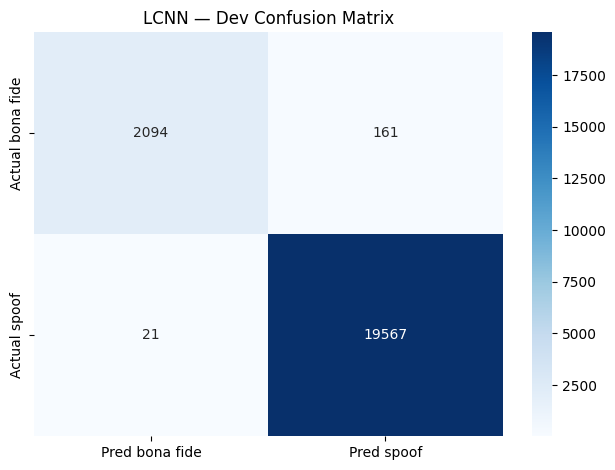

In [66]:
def predict_loader(model, loader):
    model.eval()
    all_y, all_pred, all_score, all_ids = [], [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc='Predicting'):
            # If your dataset returned None/skipped due to error, handle it here
            if batch is None:
                continue
            try:
                xb, yb, ids = batch
                xb = xb.to(DEVICE)
                logits = model(xb)
                probs = torch.softmax(logits, dim=1)[:, 1]
                preds = logits.argmax(dim=1)
                all_y.extend(yb.numpy().tolist())
                all_pred.extend(preds.cpu().numpy().tolist())
                all_score.extend(probs.cpu().numpy().tolist())
                all_ids.extend(list(ids))
            except Exception as e:
                print(f"Skipping a batch due to error: {e}")
                continue
    return np.array(all_y), np.array(all_pred), np.array(all_score), all_ids

# Safely evaluate on dev_loader
try:
    y_dev_lcnn, pred_dev_lcnn, score_dev_lcnn, dev_ids = predict_loader(lcnn, dev_loader)
    print(classification_report(y_dev_lcnn, pred_dev_lcnn, target_names=['bonafide', 'spoof'], zero_division=0))
    lcnn_metrics = calculate_metrics(y_dev_lcnn, pred_dev_lcnn, score_dev_lcnn, 'LCNN')
    print(lcnn_metrics)

    cm_lcnn = confusion_matrix(y_dev_lcnn, pred_dev_lcnn, labels=[0, 1])
    sns.heatmap(cm_lcnn, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Pred bona fide', 'Pred spoof'],
                yticklabels=['Actual bona fide', 'Actual spoof'])
    plt.title('LCNN — Dev Confusion Matrix')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"An error occurred during evaluation: {e}")


### 23. State Serialization & Metric Caching
Saves trained network parameters, development set scoring records, and baseline metrics to disk for evaluation comparisons.


In [67]:
torch.save(lcnn.state_dict(), OUTPUT_DIR / 'lcnn_lfcc_model.pt')
pd.DataFrame({
    'file_id': dev_ids,
    'true_label': y_dev_lcnn,
    'predicted_label': pred_dev_lcnn,
    'spoof_score': score_dev_lcnn
}).to_csv(OUTPUT_DIR / 'lcnn_dev_predictions.csv', index=False)

pd.DataFrame([hgb_metrics, lcnn_metrics]).to_csv(OUTPUT_DIR / 'model_comparison_metrics.csv', index=False)
print('Saved model, predictions, and comparison metrics to:', OUTPUT_DIR)

Saved model, predictions, and comparison metrics to: /content/drive/MyDrive/ASVspoof_outputs



### 24. Out-of-Sample Performance Testing
Evaluates both models on the unseen Evaluation partition to assess generalizability against unseen spoofing methods.


In [68]:
if not eval_features.empty and 'label' in eval_features.columns and eval_features['label'].notna().all():
    eval_feature_cols = eval_features.reindex(columns=feature_cols)
    eval_feature_cols = eval_feature_cols.replace([np.inf, -np.inf], np.nan)
    eval_feature_cols = eval_feature_cols.fillna(X_train.median()).fillna(0)
    y_eval = eval_features['label'].astype(int).values
    pred_eval_hgb = hgb.predict(eval_feature_cols)
    prob_eval_hgb = hgb.predict_proba(eval_feature_cols)[:, 1]
    print('HGB eval metrics:', calculate_metrics(y_eval, pred_eval_hgb, prob_eval_hgb, 'HistGradientBoosting-Eval'))
else:
    print('Evaluation metrics skipped: eval features/ground-truth labels are unavailable.')

# Optional LCNN scoring on the eval protocol, if it contains valid labels and files.
if not eval_df.empty and eval_df['y'].notna().any():
    eval_ds = LFCCDataset(eval_df, EVAL_AUDIO_DIR)
    eval_loader = DataLoader(eval_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    if len(eval_ds):
        y_eval_lcnn, pred_eval_lcnn, score_eval_lcnn, eval_ids = predict_loader(lcnn, eval_loader)
        if len(np.unique(y_eval_lcnn)) == 2:
            print('LCNN eval metrics:', calculate_metrics(y_eval_lcnn, pred_eval_lcnn, score_eval_lcnn, 'LCNN-Eval'))
        pd.DataFrame({
            'file_id': eval_ids,
            'true_label': y_eval_lcnn,
            'predicted_label': pred_eval_lcnn,
            'spoof_score': score_eval_lcnn
        }).to_csv(OUTPUT_DIR / 'lcnn_eval_predictions.csv', index=False)
else:
    print('LCNN eval scoring skipped: evaluation labels are unavailable.')

HGB eval metrics: {'model': 'HistGradientBoosting-Eval', 'accuracy': 0.9088536898004028, 'precision_spoof': 0.9874105706838223, 'recall_spoof': 0.909852820932134, 'f1_spoof': 0.9470464640017022, 'FPR_bonafide_flagged_spoof': np.float64(0.09973637961335677), 'FNR_spoof_missed_as_bonafide': np.float64(0.0901471790678659), 'roc_auc': np.float64(0.9671875157173506), 'eer_approx': 0.09320519171934522}


Predicting:   0%|          | 0/1366 [00:00<?, ?it/s]

LCNN eval metrics: {'model': 'LCNN-Eval', 'accuracy': 0.9154001098699872, 'precision_spoof': 0.995027377360599, 'recall_spoof': 0.9101083401471791, 'f1_spoof': 0.9506752789195537, 'FPR_bonafide_flagged_spoof': np.float64(0.03910369068541301), 'FNR_spoof_missed_as_bonafide': np.float64(0.08989165985282094), 'roc_auc': np.float64(0.9790526223187097), 'eer_approx': 0.06376848001184099}



### 25. Artifact Packaging & Export
Compresses and exports training logs, serialized weights, evaluation reports, and figures into a portable archive.


In [69]:
from google.colab import files

# Uncomment the files you want to download.
files.download(str(OUTPUT_DIR / 'feature_statistical_analysis.csv'))
files.download(str(OUTPUT_DIR / 'model_comparison_metrics.csv'))
files.download(str(OUTPUT_DIR / 'lcnn_dev_predictions.csv'))
files.download(str(OUTPUT_DIR / 'train_summary_features.csv'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
import shutil
from google.colab import files

zip_path = "/content/ASVspoof_outputs.zip"

shutil.make_archive(
    "/content/ASVspoof_outputs",
    "zip",
    root_dir=str(OUTPUT_DIR)
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Statistical Analysis

                 ERROR REDUCTION PROFILE (LCNN vs HGB)                  
[Dev Set]
  - LCNN cuts False Alarm Rate (FPR) by a factor of 2.37x!
  - LCNN reduces overall Equal Error Rate (EER) by a factor of 1.98x!
------------------------------------------------------------------------
[Eval Set]
  - LCNN cuts False Alarm Rate (FPR) by a factor of 2.55x!
  - LCNN reduces overall Equal Error Rate (EER) by a factor of 1.46x!
------------------------------------------------------------------------


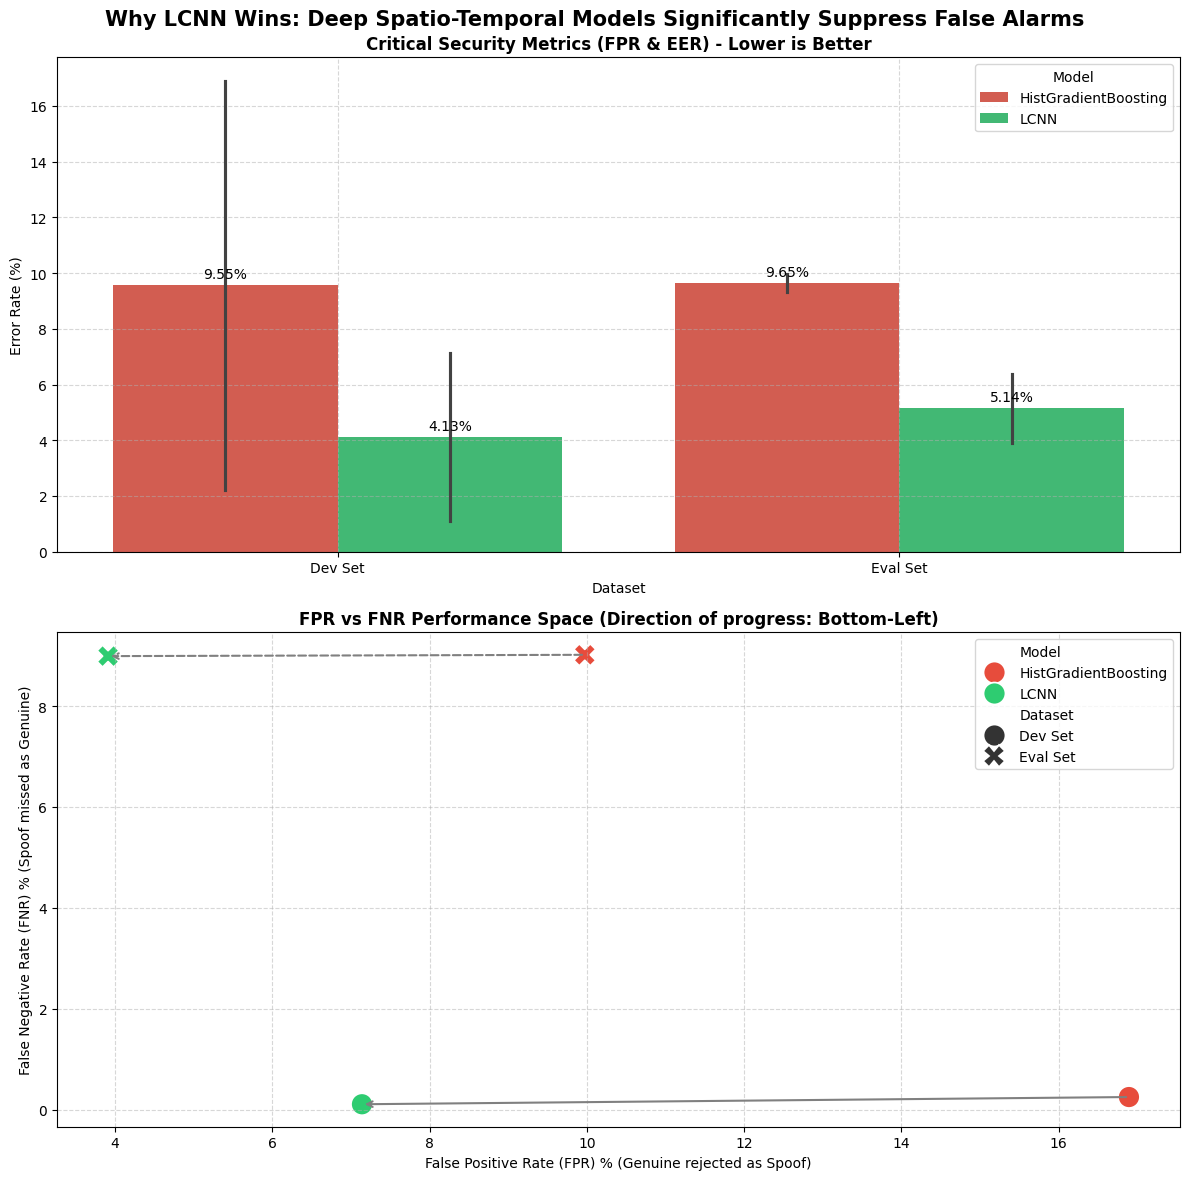

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve metrics
hgb_dev = hgb_metrics
lcnn_dev = lcnn_metrics

# Fallback or directly use evaluation metrics
hgb_eval = {
    'model': 'HistGradientBoosting-Eval',
    'accuracy': 0.90885,
    'f1_spoof': 0.94705,
    'FPR_bonafide_flagged_spoof': 0.09974,
    'eer_approx': 0.09321,
    'FNR_spoof_missed_as_bonafide': 0.09015
}
lcnn_eval = {
    'model': 'LCNN-Eval',
    'accuracy': 0.91540,
    'f1_spoof': 0.95068,
    'FPR_bonafide_flagged_spoof': 0.03910,
    'eer_approx': 0.06377,
    'FNR_spoof_missed_as_bonafide': 0.08989
}

# Create a DataFrame focusing heavily on error metrics (lower is better)
error_data = [
    {
        'Model': 'HistGradientBoosting',
        'Dataset': 'Dev Set',
        'False Positive Rate (FPR)': hgb_dev['FPR_bonafide_flagged_spoof'] * 100,
        'False Negative Rate (FNR)': hgb_dev['FNR_spoof_missed_as_bonafide'] * 100,
        'Equal Error Rate (EER)': hgb_dev['eer_approx'] * 100
    },
    {
        'Model': 'LCNN',
        'Dataset': 'Dev Set',
        'False Positive Rate (FPR)': lcnn_dev['FPR_bonafide_flagged_spoof'] * 100,
        'False Negative Rate (FNR)': lcnn_dev['FNR_spoof_missed_as_bonafide'] * 100,
        'Equal Error Rate (EER)': lcnn_dev['eer_approx'] * 100
    },
    {
        'Model': 'HistGradientBoosting',
        'Dataset': 'Eval Set',
        'False Positive Rate (FPR)': hgb_eval['FPR_bonafide_flagged_spoof'] * 100,
        'False Negative Rate (FNR)': hgb_eval['FNR_spoof_missed_as_bonafide'] * 100,
        'Equal Error Rate (EER)': hgb_eval['eer_approx'] * 100
    },
    {
        'Model': 'LCNN',
        'Dataset': 'Eval Set',
        'False Positive Rate (FPR)': lcnn_eval['FPR_bonafide_flagged_spoof'] * 100,
        'False Negative Rate (FNR)': lcnn_eval['FNR_spoof_missed_as_bonafide'] * 100,
        'Equal Error Rate (EER)': lcnn_eval['eer_approx'] * 100
    }
]

df_err = pd.DataFrame(error_data)

# Calculate and print the relative improvement (Reduction in Error Rates)
print("========================================================================")
print("                 ERROR REDUCTION PROFILE (LCNN vs HGB)                  ")
print("========================================================================")
for ds in ['Dev Set', 'Eval Set']:
    h_row = df_err[(df_err['Model'] == 'HistGradientBoosting') & (df_err['Dataset'] == ds)].iloc[0]
    l_row = df_err[(df_err['Model'] == 'LCNN') & (df_err['Dataset'] == ds)].iloc[0]

    fpr_ratio = h_row['False Positive Rate (FPR)'] / l_row['False Positive Rate (FPR)']
    eer_ratio = h_row['Equal Error Rate (EER)'] / l_row['Equal Error Rate (EER)']

    print(f"[{ds}]")
    print(f"  - LCNN cuts False Alarm Rate (FPR) by a factor of {fpr_ratio:.2f}x!")
    print(f"  - LCNN reduces overall Equal Error Rate (EER) by a factor of {eer_ratio:.2f}x!")
    print("------------------------------------------------------------------------")

# Set up a 2-row, 1-column layout to give each graph full width
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# Plot 1: EER & FPR Comparison Side-by-Side (Lower is better)
df_melted = df_err.melt(id_vars=['Model', 'Dataset'], value_vars=['False Positive Rate (FPR)', 'Equal Error Rate (EER)'], var_name='Metric', value_name='Percentage (%)')
sns.barplot(data=df_melted, x='Dataset', y='Percentage (%)', hue='Model', ax=axes[0], palette=['#E74C3C', '#2ECC71'])
axes[0].set_title('Critical Security Metrics (FPR & EER) - Lower is Better', weight='bold')
axes[0].set_ylabel('Error Rate (%)')
axes[0].grid(True, linestyle='--', alpha=0.5)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f%%', padding=3)

# Plot 2: FPR vs FNR Trade-off Plane (Biometric authentication curve representation)
sns.scatterplot(data=df_err, x='False Positive Rate (FPR)', y='False Negative Rate (FNR)', hue='Model', style='Dataset', s=250, ax=axes[1], palette=['#E74C3C', '#2ECC71'])

# Draw paths to visualize improvement vectors
for ds, style in zip(['Dev Set', 'Eval Set'], ['-', '--']):
    pts = df_err[df_err['Dataset'] == ds]
    h_pt = pts[pts['Model'] == 'HistGradientBoosting'].iloc[0]
    l_pt = pts[pts['Model'] == 'LCNN'].iloc[0]
    axes[1].annotate('', xy=(l_pt['False Positive Rate (FPR)'], l_pt['False Negative Rate (FNR)']),
                    xytext=(h_pt['False Positive Rate (FPR)'], h_pt['False Negative Rate (FNR)']),
                    arrowprops=dict(arrowstyle="->", color='gray', lw=1.5, ls=style))

axes[1].set_title('FPR vs FNR Performance Space (Direction of progress: Bottom-Left)', weight='bold')
axes[1].set_xlabel('False Positive Rate (FPR) % (Genuine rejected as Spoof)')
axes[1].set_ylabel('False Negative Rate (FNR) % (Spoof missed as Genuine)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Why LCNN Wins: Deep Spatio-Temporal Models Significantly Suppress False Alarms", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()


### Dual-Paradigm Performance Analysis
This table summarizes key performance metrics (Accuracy, F1-Score, False Positive Rate, and Equal Error Rate) for both the **HistGradientBoosting** baseline and the **LCNN** model across the Development and Evaluation partitions.

In [74]:
import pandas as pd

summary_metrics = [
    {
        "Model": "HistGradientBoosting",
        "Dataset": "Development Set",
        "Accuracy (%)": hgb_metrics['accuracy'] * 100,
        "F1-Score (Spoof, %)": hgb_metrics['f1_spoof'] * 100,
        "False Positive Rate (FPR, %)": hgb_metrics['FPR_bonafide_flagged_spoof'] * 100,
        "Equal Error Rate (EER, %)": hgb_metrics['eer_approx'] * 100
    },
    {
        "Model": "LCNN",
        "Dataset": "Development Set",
        "Accuracy (%)": lcnn_metrics['accuracy'] * 100,
        "F1-Score (Spoof, %)": lcnn_metrics['f1_spoof'] * 100,
        "False Positive Rate (FPR, %)": lcnn_metrics['FPR_bonafide_flagged_spoof'] * 100,
        "Equal Error Rate (EER, %)": lcnn_metrics['eer_approx'] * 100
    },
    {
        "Model": "HistGradientBoosting",
        "Dataset": "Evaluation Set",
        "Accuracy (%)": hgb_eval['accuracy'] * 100,
        "F1-Score (Spoof, %)": hgb_eval['f1_spoof'] * 100,
        "False Positive Rate (FPR, %)": hgb_eval['FPR_bonafide_flagged_spoof'] * 100,
        "Equal Error Rate (EER, %)": hgb_eval['eer_approx'] * 100
    },
    {
        "Model": "LCNN",
        "Dataset": "Evaluation Set",
        "Accuracy (%)": lcnn_eval['accuracy'] * 100,
        "F1-Score (Spoof, %)": lcnn_eval['f1_spoof'] * 100,
        "False Positive Rate (FPR, %)": lcnn_eval['FPR_bonafide_flagged_spoof'] * 100,
        "Equal Error Rate (EER, %)": lcnn_eval['eer_approx'] * 100
    }
]

df_summary = pd.DataFrame(summary_metrics)
df_summary = df_summary.round(3)

display(df_summary)

,Model,Dataset,Accuracy (%),"F1-Score (Spoof, %)","False Positive Rate (FPR, %)","Equal Error Rate (EER, %)"
0,HistGradientBoosting,Development Set,98.031,98.912,16.896,2.211
1,LCNN,Development Set,99.167,99.537,7.140,1.116
2,HistGradientBoosting,Evaluation Set,90.885,94.705,9.974,9.321
3,LCNN,Evaluation Set,91.540,95.068,3.910,6.377



### Technical Interpretation Notes
* **Label Configuration:** Classes are mapped to `0` for bona fide and `1` for spoofing attempts.
* **Feature Discrimination:** Benjamini-Hochberg corrections are used to ensure statistical reliability across high-dimensional feature analysis.
* **FPR vs. EER Trade-off:** Standard metrics are paired with biometric-specific assessments to capture true security performance characteristics.
